# Hacker News — Topic Clustering of Story Titles

**Input:** the preprocessed dataset (one row per eligible story, with `title`, `viral`, `split` and the static features).

**Steps:** clean titles → sentence embeddings (Hugging Face) → optional UMAP → choose *k* (silhouette + readability) → K-Means fit on **train stories only** → inspect clusters → export a sample sheet for naming → viral rate per topic → 2D map → does topic improve prediction?

Install once: `pip install sentence-transformers umap-learn scikit-learn pandas matplotlib openpyxl`
(UMAP is optional; the notebook falls back to PCA without it.)

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, average_precision_score, roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# ======================= Configuration =======================
DATA = Path("7-days-scraping_preprocessed.csv")
OUT_DIR = Path("clustering")
MODELS = ["sentence-transformers/all-mpnet-base-v2",   # main model
          "sentence-transformers/all-MiniLM-L6-v2"]    # fast comparison (remove to save time)
USE_UMAP = True          # reduce to UMAP_DIMS before K-Means (cleaner clusters); falls back if not installed
UMAP_DIMS = 10
K_RANGE = range(6, 21)   # k values to score
K_PICK_RANGE = (8, 12)   # auto-pick the best silhouette inside this range (enough viral posts per cluster)
K = None                 # set an int to override the automatic choice after looking at the plot
N_CENTRAL, N_RANDOM = 20, 15   # titles per cluster in the export sheet
RANDOM_STATE = 42
# =============================================================
OUT_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 110

## 1. Load and clean titles
The `Show/Ask/Tell HN:` prefixes and tags like `[video]`, `[pdf]`, `(2019)` are removed so clusters form around the topic, not the format (the prefixes and media tags remain as separate features).

In [2]:
df = pd.read_csv(DATA, parse_dates=["submit_time"]).set_index("id")
PREFIX = re.compile(r"^\s*(show|ask|tell|launch)\s+hn\s*[:\-–—]?\s*", re.I)
TAGS = re.compile(r"\s*[\[(](?:video|pdf|audio|\d{4})[\])]", re.I)   # "[video]", "[pdf]", "(2019)"
df["clean_title"] = (df["title"].fillna("").str.replace(PREFIX, "", regex=True)
                       .str.replace(TAGS, "", regex=True).str.strip())
df.loc[df["clean_title"] == "", "clean_title"] = df["title"]
train_mask = (df["split"] == "train").to_numpy()

print(f"Stories: {len(df):,}  | train {train_mask.sum():,} / test {(~train_mask).sum():,}")
print(f"Viral: {df['viral'].sum()} ({df['viral'].mean():.1%})")
df[["title", "clean_title"]].sample(5, random_state=1)

Stories: 6,736  | train 5,388 / test 1,348
Viral: 222 (3.3%)


,title,clean_title
id,,
50485295,Brazil's Caixa insurer breach exposes names an...,Brazil's Caixa insurer breach exposes names an...
50434431,Show HN: I abandoned my AVX2 128-bit fixed-poi...,I abandoned my AVX2 128-bit fixed-point library
50424233,"The case for and against local, personal AI","The case for and against local, personal AI"
50445429,Why Everything in Moderation Is a Philosophica...,Why Everything in Moderation Is a Philosophica...
50427953,The AI Boom Goes Nuclear,The AI Boom Goes Nuclear


## 2. Sentence embeddings
Embeddings are L2-normalized (so K-Means ≈ cosine clustering) and cached to `.npy`, so each model runs only once.

In [3]:
def embed(model_name, texts):
    cache = OUT_DIR / f"emb_{model_name.split('/')[-1]}.npy"
    if cache.exists():
        emb = np.load(cache)
        if len(emb) == len(texts):
            print(f"{model_name}: loaded from cache {emb.shape}")
            return emb
    try:
        from sentence_transformers import SentenceTransformer
        model = SentenceTransformer(model_name)
        emb = model.encode(list(texts), batch_size=64, show_progress_bar=True,
                           normalize_embeddings=True)
    except ImportError:
        # Fallback only so the notebook still runs; install sentence-transformers for real results
        print("sentence-transformers not installed -> TF-IDF + SVD fallback")
        from sklearn.decomposition import TruncatedSVD
        tf = TfidfVectorizer(stop_words="english", min_df=2).fit_transform(texts)
        emb = TruncatedSVD(100, random_state=RANDOM_STATE).fit_transform(tf)
        emb /= np.linalg.norm(emb, axis=1, keepdims=True).clip(1e-9)
        return emb                      # fallback is never cached
    np.save(cache, emb)
    print(f"{model_name}: {emb.shape}")
    return emb

embeddings = {m: embed(m, df["clean_title"]) for m in MODELS}

/home/ketsuno/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 106/106 [00:05<00:00, 19.36it/s]


sentence-transformers/all-mpnet-base-v2: (6736, 768)


Batches: 100%|██████████| 106/106 [00:01<00:00, 87.35it/s] 

sentence-transformers/all-MiniLM-L6-v2: (6736, 384)


## 3. Optional UMAP reduction
K-Means struggles in 384–768 dimensions; UMAP to ~10 dims usually gives tighter, more separated clusters. Fit on train only, then applied to test.

In [4]:
try:
    import umap
    HAVE_UMAP = True
except ImportError:
    HAVE_UMAP = False
    print("umap-learn not installed -> clustering on the raw embeddings")

def reduce(emb):
    if not (USE_UMAP and HAVE_UMAP):
        return emb
    reducer = umap.UMAP(n_components=UMAP_DIMS, n_neighbors=15, min_dist=0.0,
                        metric="cosine", random_state=RANDOM_STATE)
    reducer.fit(emb[train_mask])
    return reducer.transform(emb)

spaces = {m: reduce(e) for m, e in embeddings.items()}
print({m.split('/')[-1]: s.shape for m, s in spaces.items()})

/tmp/ipykernel_773957/3808157805.py:13: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  reducer.fit(emb[train_mask])
/home/ketsuno/.local/lib/python3.14/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_773957/3808157805.py:13: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive i

{'all-mpnet-base-v2': (6736, 10), 'all-MiniLM-L6-v2': (6736, 10)}


## 4. Choose *k*
Silhouette score per *k* on the train stories (higher = better separated). The plot guides the choice; readability of the clusters (step 6) decides.

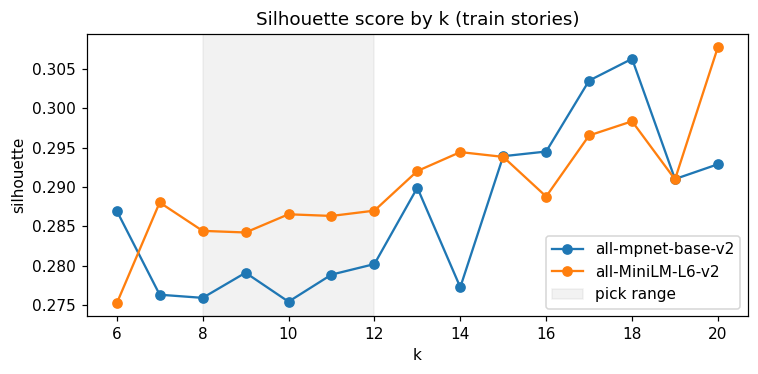

,all-mpnet-base-v2,all-MiniLM-L6-v2
6,0.2870,0.2752
7,0.2763,0.2880
8,0.2759,0.2844
9,0.2791,0.2842
10,0.2754,0.2865
11,0.2789,0.2863
12,0.2802,0.2870
13,0.2899,0.2920
14,0.2773,0.2944
15,0.2939,0.2938


In [5]:
scores = {}
for m, X in spaces.items():
    Xtr = X[train_mask]
    scores[m] = {}
    for k in K_RANGE:
        km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Xtr)
        scores[m][k] = silhouette_score(Xtr, km.labels_, sample_size=min(4000, len(Xtr)),
                                        random_state=RANDOM_STATE)
scores = pd.DataFrame(scores)
scores.columns = [c.split("/")[-1] for c in scores.columns]

ax = scores.plot(marker="o", figsize=(7, 3.5), title="Silhouette score by k (train stories)")
ax.axvspan(*K_PICK_RANGE, alpha=0.1, color="grey", label="pick range")
ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "silhouette_by_k.png"); plt.show()
scores.round(4)

In [6]:
MAIN = MODELS[0]
in_range = scores.loc[K_PICK_RANGE[0]:K_PICK_RANGE[1], MAIN.split("/")[-1]]
k_final = K if K else int(in_range.idxmax())
print(f"Main model: {MAIN}  ->  k = {k_final}  (silhouette {scores.loc[k_final, MAIN.split('/')[-1]]:.3f})")

Main model: sentence-transformers/all-mpnet-base-v2  ->  k = 12  (silhouette 0.280)


## 5. Final clustering
Fit on train stories, `predict` on test stories (the test set stays unseen). Distance to the centre is kept to find the most typical titles.

In [7]:
X = spaces[MAIN]
km = KMeans(k_final, n_init=20, random_state=RANDOM_STATE).fit(X[train_mask])
df["cluster"] = km.predict(X)
df["distance"] = np.linalg.norm(X - km.cluster_centers_[df["cluster"]], axis=1)

sizes = (df.groupby("cluster")
           .agg(stories=("title", "size"), train=("split", lambda s: (s == "train").sum()),
                viral=("viral", "sum"), viral_rate=("viral", "mean"))
           .sort_values("stories", ascending=False))
sizes["viral_rate"] = (sizes["viral_rate"] * 100).round(1)
sizes

,stories,train,viral,viral_rate
cluster,,,,
1,719,550,16,2.2
6,715,585,22,3.1
5,706,595,25,3.5
4,676,536,12,1.8
2,624,523,17,2.7
0,562,453,21,3.7
10,549,430,23,4.2
8,498,407,19,3.8
11,459,372,13,2.8


## 6. Inspect clusters
Top distinctive words per cluster (class-based TF-IDF) and the 8 most central titles. If a cluster can't be named, try another `K` in the config.

In [8]:
# class-based TF-IDF: one "document" per cluster -> words typical of that cluster vs the others
docs = df.groupby("cluster")["clean_title"].apply(" ".join)
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, sublinear_tf=True)
M = tfidf.fit_transform(docs)
vocab = np.array(tfidf.get_feature_names_out())
top_words = {c: ", ".join(vocab[M[i].toarray().ravel().argsort()[::-1][:10]])
             for i, c in enumerate(docs.index)}

for c in sizes.index:
    print(f"\n=== Cluster {c}  |  {sizes.loc[c, 'stories']} stories, "
          f"{sizes.loc[c, 'viral']} viral ({sizes.loc[c, 'viral_rate']}%)")
    print("   words:", top_words[c])
    for t in df[df["cluster"] == c].nsmallest(8, "distance")["title"]:
        print("   -", t)


=== Cluster 1  |  719 stories, 16 viral (2.2%)
   words: decision, slop, ai, using ai, ai slop, artificial intelligence, ai models, intelligence, brain, age ai
   - How A.I. Just Blew Up a Key Tenet of Computer Science
   - AI and the Art of Work
   - Ask HN What to learn for AI Researcher interview?
   - ThinkStream – AI generates the work. We still need to understand it
   - Ask HN: How do you care about a project that is predominately generated by AI?
   - Taxonomy of 26 Ways AI Can Make Your Life Worse
   - Generalist vs. Specialist in the After AI Era
   - The 15-Day Clock: Could You Reconstruct an AI Incident Before the Deadline?

=== Cluster 6  |  715 stories, 22 viral (3.1%)
   words: blood, water, early, climate, brain, man, health, scientists, lives, life
   - To Catch a Falling Knife
   - How to Become a Lost
   - How to Become a Lost
   - RIP, Harvest
   - How Product Hunt Almost Died
   - Dark Forestry
   - The Afterlife of the Berlin Wall
   - Romania sets new world reco

## 7. Export the sample sheet (for naming the clusters)
`clusters_for_naming.xlsx`: sheet **samples** = central + random titles per cluster, sheet **sizes** = counts and top words. `cluster_assignments.csv` keeps the cluster of every story.

In [9]:
rows = []
for c in sizes.index:
    g = df[df["cluster"] == c]
    central = g.nsmallest(N_CENTRAL, "distance").assign(kind="central")
    rest = g.drop(central.index)
    random = rest.sample(min(N_RANDOM, len(rest)), random_state=RANDOM_STATE).assign(kind="random")
    rows.append(pd.concat([central, random]))
samples = (pd.concat(rows).reset_index()
             [["cluster", "kind", "title", "distance", "id"]].round({"distance": 4}))

sheet_sizes = sizes.assign(top_words=[top_words[c] for c in sizes.index]).reset_index()
with pd.ExcelWriter(OUT_DIR / "clusters_for_naming.xlsx") as xl:
    samples.to_excel(xl, sheet_name="samples", index=False)
    sheet_sizes.to_excel(xl, sheet_name="sizes", index=False)
df[["cluster", "distance", "split", "viral"]].to_csv(OUT_DIR / "cluster_assignments.csv")
print("Saved:", OUT_DIR / "clusters_for_naming.xlsx", "and", OUT_DIR / "cluster_assignments.csv")

Saved: clustering/clusters_for_naming.xlsx and clustering/cluster_assignments.csv


## 8. Name the clusters
Fill in the names once they're decided, then re-run from here (no need to re-embed). Unnamed clusters show as `Cluster N`.

In [10]:
CLUSTER_NAMES = {
    # 0: "AI / LLMs",
    # 1: "Programming languages",
}
df["topic"] = df["cluster"].map(lambda c: CLUSTER_NAMES.get(c, f"Cluster {c}"))

## 9. Which topics go viral?
Viral rate per topic, with story and viral counts. Clusters with few viral stories have wide uncertainty, so small differences aren't meaningful.

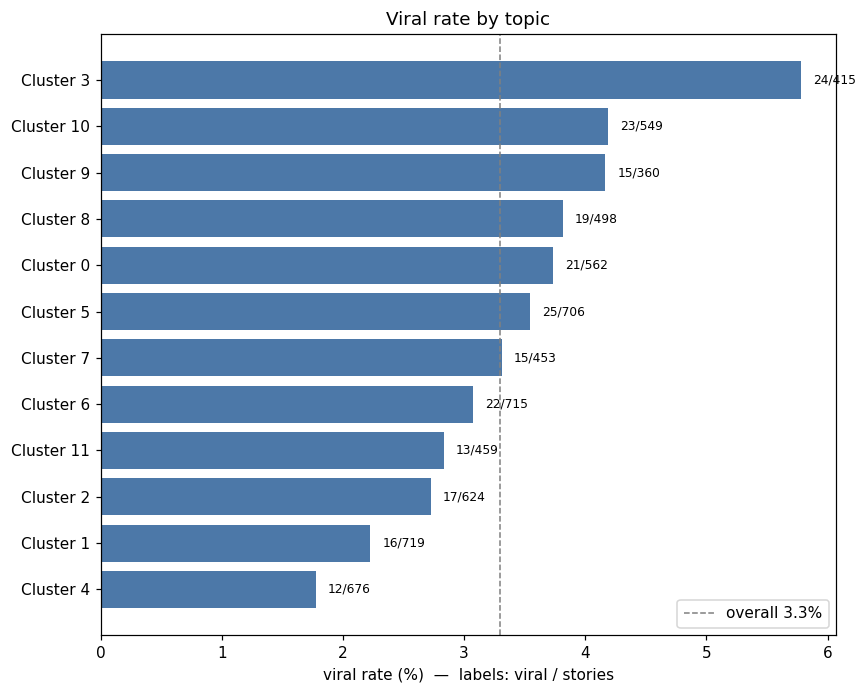

In [11]:
topic = (df.groupby("topic").agg(stories=("viral", "size"), viral=("viral", "sum"))
           .assign(rate=lambda t: t["viral"] / t["stories"] * 100)
           .sort_values("rate"))
overall = df["viral"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 0.45 * len(topic) + 1))
ax.barh(topic.index, topic["rate"], color="#4C78A8")
ax.axvline(overall, color="grey", ls="--", lw=1, label=f"overall {overall:.1f}%")
for i, (r, v, n) in enumerate(zip(topic["rate"], topic["viral"], topic["stories"])):
    ax.text(r + 0.1, i, f"{v}/{n}", va="center", fontsize=8)
ax.set_xlabel("viral rate (%)  —  labels: viral / stories")
ax.set_title("Viral rate by topic"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT_DIR / "viral_rate_by_topic.png"); plt.show()

## 10. 2D map of the topics
Each dot is a story, coloured by topic; viral stories are drawn larger with a black edge.

/home/ketsuno/.local/lib/python3.14/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/ketsuno/.local/lib/python3.14/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


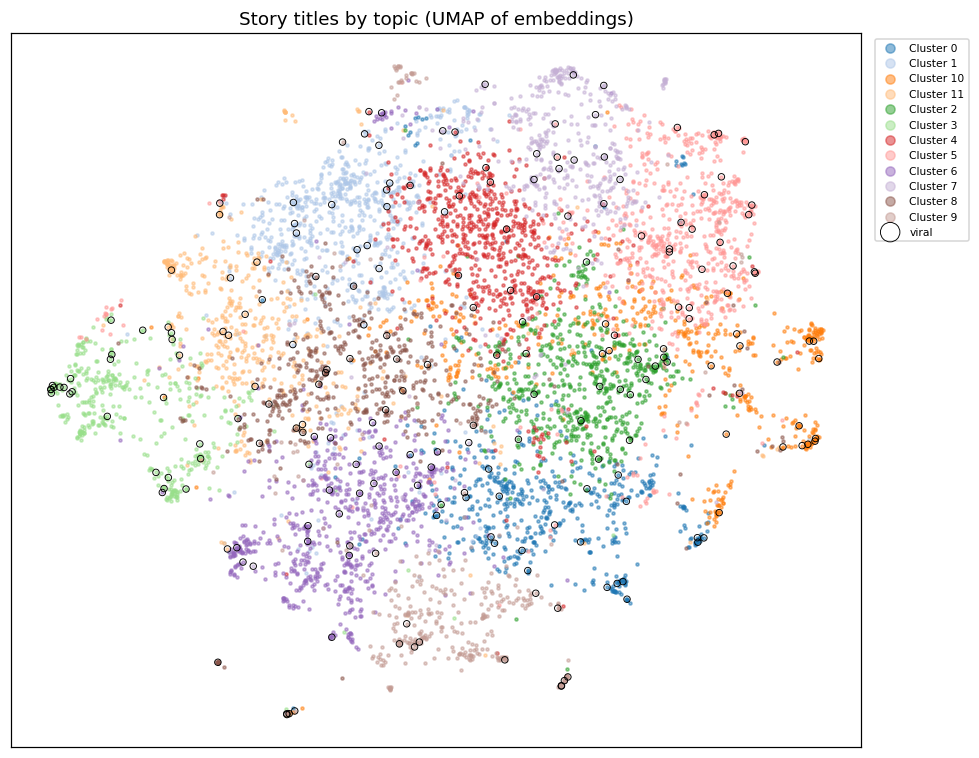

In [12]:
emb = embeddings[MAIN]
if HAVE_UMAP:
    xy = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine",
                   random_state=RANDOM_STATE).fit_transform(emb)
else:
    from sklearn.decomposition import PCA
    xy = PCA(2, random_state=RANDOM_STATE).fit_transform(emb)

fig, ax = plt.subplots(figsize=(9, 7))
cmap = plt.get_cmap("tab20")
for i, t in enumerate(sorted(df["topic"].unique())):
    m = (df["topic"] == t).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=4, alpha=0.5, color=cmap(i % 20), label=t)
v = (df["viral"] == 1).to_numpy()
ax.scatter(xy[v, 0], xy[v, 1], s=18, facecolors="none", edgecolors="black", lw=0.6, label="viral")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Story titles by topic (UMAP of embeddings)" if HAVE_UMAP else "Story titles by topic (PCA)")
ax.legend(markerscale=3, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(OUT_DIR / "topic_map.png", bbox_inches="tight"); plt.show()

## 11. Does topic help predict virality?
Same logistic regression as the preprocessing baseline, on the **static features** (known at posting time), with and without the one-hot topic. Evaluated with CV on train and on the held-out time-split test set. A random model's PR-AUC ≈ the viral rate.

In [13]:
STATIC = ["title_len", "title_words", "is_show_hn", "is_ask_hn", "is_tell_hn", "has_question",
          "has_number", "has_media_tag", "has_caps_word", "is_self_post", "is_github",
          "is_youtube", "is_pdf_url", "hour_sin", "hour_cos"]
ENGAGEMENT = ["score_at_N", "comments_at_N", "best_new_rank", "best_top_rank", "n_obs_in_window",
              "score_gain_2nd_half", "score_per_min", "comments_per_min", "comments_per_point",
              "on_front_page_by_N"]
STATIC = [c for c in STATIC if c in df.columns]
ENGAGEMENT = [c for c in ENGAGEMENT if c in df.columns]
topic_dummies = pd.get_dummies(df["cluster"], prefix="topic", dtype=float)
data = pd.concat([df, topic_dummies], axis=1)
TOPIC = list(topic_dummies.columns)

tr, te = data[data["split"] == "train"], data[data["split"] == "test"]
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

def run(cols, name):
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(class_weight="balanced", C=0.3, max_iter=5000))
    cv_ap = cross_val_score(model, tr[cols], tr["viral"], cv=cv, scoring="average_precision")
    model.fit(tr[cols], tr["viral"])
    p = model.predict_proba(te[cols])[:, 1]
    return {"features": name, "CV PR-AUC (train)": f"{cv_ap.mean():.3f} ± {cv_ap.std():.3f}",
            "test PR-AUC": round(average_precision_score(te["viral"], p), 3),
            "test ROC-AUC": round(roc_auc_score(te["viral"], p), 3)}

results = pd.DataFrame([
    run(STATIC, "static"),
    run(STATIC + TOPIC, "static + topic"),
    run(ENGAGEMENT + STATIC, "engagement + static"),
    run(ENGAGEMENT + STATIC + TOPIC, "engagement + static + topic"),
])
print(f"Random-model PR-AUC ≈ train {tr['viral'].mean():.3f} / test {te['viral'].mean():.3f}")
results.to_csv(OUT_DIR / "topic_feature_results.csv", index=False)
results

Random-model PR-AUC ≈ train 0.030 / test 0.043


,features,CV PR-AUC (train),test PR-AUC,test ROC-AUC
0,static,0.043 ± 0.005,0.082,0.594
1,static + topic,0.045 ± 0.007,0.065,0.601
2,engagement + static,0.677 ± 0.066,0.685,0.945
3,engagement + static + topic,0.673 ± 0.065,0.652,0.928
